# Русский IOI: функциональные головы и причинная схема ruGPT3Small

**Цель.** Проверить, есть ли у русскоязычной `ai-forever/rugpt3small_based_on_gpt2` механизмы IOI (*Indirect Object Identification*), похожие на обнаруженные в GPT-2 Small в [Wang et al., 2022](https://arxiv.org/abs/2211.00593). Мы **не переносим заранее номера голов**: сначала ищем компоненты, затем проверяем их функции и связи.

**Маршрут исследования:** русские примеры → поведение модели → карты внимания → activation patching 144 голов → валидация и mean ablation → функциональные признаки → изолированный path patching → сохранение эффекта выделенным circuit.

**Как читать визуализации:** `D = log P(правильное имя) − log P(неправильное имя)` с учётом **всех токенов** дательного падежа. `D > 0` означает, что модель предпочитает ожидаемого получателя. Положительное изменение `D` после патчинга — влияние **конкретного вмешательства**, а не автоматическое доказательство того, что голова является Name Mover.

**Воспроизводимость:** T4 GPU в Google Colab; внешние `.py` и архивы не нужны. Всего **20 ячеек**, результаты и графики сохраняются в `ru_ioi_results/`. Финальные имена используются один раз после выбора гипотез.

In [1]:
# Подготовка. Устанавливаем совместимые зависимости Colab.
%pip install -q "transformer-lens==4.2.0" "pandas==2.2.3" "matplotlib<4" "huggingface_hub" "tqdm"

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 38.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.6/56.6 kB 6.2 MB/s eta 0:00:00


## 1. Модель, датасет и исходное поведение

Загружаем ruGPT3Small (12 слоёв × 12 голов), фиксируем параметры и создаём пары русских предложений. В каждом условии есть два порядка имён, два действующих лица и два шаблона. **Меняем только действующее лицо**, затем смотрим, как меняется предпочтение получателя.

Разделяем имена на *поиск*, *проверку* и *финальный тест*: одинаковые имена не должны одновременно служить основанием для выбора головы и окончательным доказательством. В основной выборке сравниваем имена с одинаковым числом токенов; это ограничение будет указано в выводах.

In [2]:
# Этап 1. Загружаем модель и фиксируем параметры воспроизводимости.
import os, json, random, gc, warnings
from pathlib import Path
from importlib.metadata import version
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display
from transformer_lens.model_bridge import TransformerBridge

SEED = 2026
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
assert DEVICE == "cuda", "Для полного исследования включите T4 GPU в Colab"
MODEL_ID = "ai-forever/rugpt3small_based_on_gpt2"
MODEL_REV = "a9307e696cd3c5b7f953ff4cb19d76a4d81821d5"
OUT = Path("ru_ioi_results"); OUT.mkdir(exist_ok=True)
model = TransformerBridge.boot_transformers(
    MODEL_ID, revision=MODEL_REV, device=DEVICE, dtype=torch.float32
)
model.enable_compatibility_mode()
model.eval()
N_LAYERS, N_HEADS = model.cfg.n_layers, model.cfg.n_heads
assert (N_LAYERS, N_HEADS) == (12, 12)
tokenizer = model.tokenizer
assert tokenizer.is_fast, "Нужен fast-токенизатор с offset_mapping"
print("GPU:", torch.cuda.get_device_name(0))
print("TransformerLens:", version("transformer-lens"), "Голов:", N_LAYERS * N_HEADS)

def to_ids(text):
    return model.to_tokens(text).to(DEVICE)

# Ограничиваем стоимость первичного поиска, не меняя размер итоговой выборки.
DISCOVERY_LIMIT = 16      # Можно поднять до 32 для повторной проверки
PATH_LIMIT = 6           # Контроль путей: несколько пар и шаблонов
TOP_PER_POSITION = 6     # Кандидаты на позиции END и S2
plt.rcParams.update({"figure.dpi": 110, "font.family": "DejaVu Sans"})

config.json:   0%|          | 0.00/720 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  551MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/149 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  551MB            

...

tokenizer_config.json:   0%|          | 0.00/1.25k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.71M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.27M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/574 [00:00<?, ?B/s]

GPU: Tesla T4
TransformerLens: 4.2.0 Голов: 144


In [3]:
# Этап 1. Создаём парные русские примеры и независимые выборки.
# Форма «Катя» — именительный падеж, «Кате» — дательный падеж.
NAME_PAIRS = [
    (("Аня", "Ане"), ("Катя", "Кате")),
    (("Маша", "Маше"), ("Даша", "Даше")),
    (("Лена", "Лене"), ("Вера", "Вере")),
    (("Оля", "Оле"), ("Соня", "Соне")),
    (("Ира", "Ире"), ("Таня", "Тане")),
    (("Нина", "Нине"), ("Зоя", "Зое")),
    (("Юля", "Юле"), ("Лиза", "Лизе")),
    (("Настя", "Насте"), ("Галя", "Гале")),
]
FINAL_PAIRS = [
    (("Кира", "Кире"), ("Алла", "Алле")),
    (("Рита", "Рите"), ("Вика", "Вике")),
    (("Люба", "Любе"), ("Надя", "Наде")),
    (("Лида", "Лиде"), ("Света", "Свете")),
]
TEMPLATES = [
    "{a} и {b} пришли в офис. {s} передала письмо",
    "{a} и {b} встретились утром. {s} подарила открытку",
]

def build_rows(pairs, split):
    result = []
    for pair_id, (name_a, name_b) in enumerate(pairs):
        for template_id, template in enumerate(TEMPLATES):
            for order in (0, 1):
                a, b = (name_a, name_b) if order == 0 else (name_b, name_a)
                for subject_id, subject in enumerate((name_a, name_b)):
                    recipient = name_b if subject_id == 0 else name_a
                    other = recipient
                    clean = template.format(a=a[0], b=b[0], s=subject[0])
                    corrupted = template.format(a=a[0], b=b[0], s=other[0])
                    result.append(dict(
                        id=f"{split}_{pair_id}_{template_id}_{order}_{subject_id}",
                        split=split, pair_id=pair_id, template_id=template_id,
                        order=order, subject_id=subject_id,
                        clean=clean, corrupted=corrupted,
                        subject=subject[0], recipient=recipient[0],
                        clean_s2=subject[0], corrupted_s2=recipient[0],
                        correct=" " + recipient[1], wrong=" " + subject[1],
                    ))
    return result

all_rows = build_rows(NAME_PAIRS, "development")
final_rows = build_rows(FINAL_PAIRS, "final")
# Выделяем имена для поиска и валидации заранее; финальная выборка не используется при выборе голов.
discovery_ids, validation_ids = {0, 1, 2, 4, 6}, {3, 5, 7}

def prompt_prefix_ok(prompt, answer):
    pref, full = to_ids(prompt)[0], to_ids(prompt + answer)[0]
    return len(full) > len(pref) and torch.equal(pref, full[:len(pref)])

def permitted(row):
    return (all(prompt_prefix_ok(row[key], row[cand])
                for key in ("clean", "corrupted")
                for cand in ("correct", "wrong"))
            and len(to_ids(row["clean"])[0]) == len(to_ids(row["corrupted"])[0])
            and len(to_ids(row["clean"] + row["correct"])[0]) - len(to_ids(row["clean"])[0])
                == len(to_ids(row["clean"] + row["wrong"])[0]) - len(to_ids(row["clean"])[0]))

eligible = [r for r in all_rows if permitted(r)]
discovery = [r for r in eligible if r["pair_id"] in discovery_ids]
validation = [r for r in eligible if r["pair_id"] in validation_ids]
final_valid = [r for r in final_rows if permitted(r)]
# Обе версии (два субъекта) одного условия должны присутствовать вместе.
def only_complete_pairs(dataset):
    keys = {}
    for r in dataset:
        key = (r["pair_id"], r["template_id"], r["order"])
        keys.setdefault(key, set()).add(r["subject_id"])
    return [r for r in dataset if keys[r["pair_id"], r["template_id"], r["order"]] == {0, 1}]

discovery = only_complete_pairs(discovery)
validation = only_complete_pairs(validation)
final_valid = only_complete_pairs(final_valid)
assert len(discovery) >= 8 and len(validation) >= 4 and len(final_valid) >= 4, "Недостаточно подходящих примеров; проверьте токенизацию"
# Стратифицированный пилот: покрываем все пары имён, оба шаблона и оба субъекта.
# Встречные варианты не разрываем, чтобы эффект был парным.
conditions={}
for r in discovery:
    key=(r["pair_id"],r["template_id"],r["order"])
    conditions.setdefault(key, []).append(r)
assert all(len(v)==2 for v in conditions.values())
by_pair={p:[] for p in sorted(discovery_ids)}
for key, values in conditions.items():
    by_pair[key[0]].append((key,values))
rng=np.random.default_rng(SEED)
for p in by_pair:
    rng.shuffle(by_pair[p])
chosen=[]
for round_index in range(max(map(len,by_pair.values()))):
    for p in sorted(by_pair):
        if round_index < len(by_pair[p]): chosen.append(by_pair[p][round_index])
scan_rows=[r for _,two in chosen[:DISCOVERY_LIMIT//2] for r in sorted(two,key=lambda x:x["subject_id"])]
print("Доступно: поиск", len(discovery), "проверка", len(validation), "финал", len(final_valid))
print("Сканируем:", len(scan_rows), "примеров; финальные имена скрыты до последнего теста")
print("Пример:", scan_rows[0]["clean"], "→", scan_rows[0]["correct"])

Доступно: поиск 32 проверка 16 финал 24
Сканируем: 16 примеров; финальные имена скрыты до последнего теста
Пример: Катя и Аня встретились утром. Аня подарила открытку →  Кате


Исходное качество:   0%|          | 0/48 [00:00<?, ?it/s]

,D_clean,D_corrupted,contrast
split,,,
discovery,0.885,-0.885,1.771
validation,0.722,-0.722,1.444


Точность выбора между двумя именами: {'discovery': 0.844, 'validation': 0.5}
У каждого условия два встречных варианта; их нельзя считать независимыми наблюдениями.


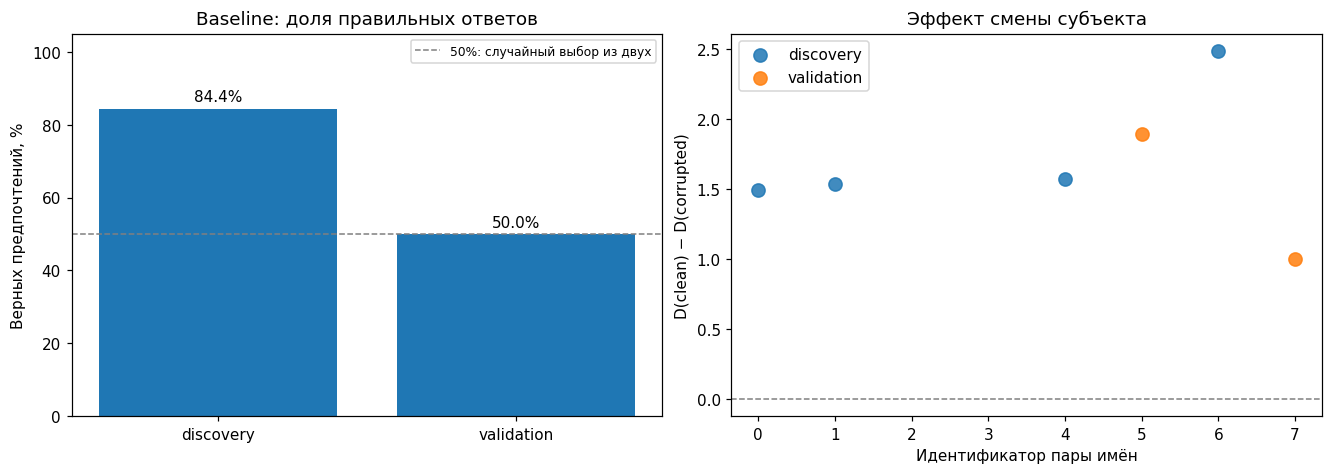

**Вывод этапа:** поведение модели сначала оценивается отдельно от поиска голов. Точность на проверке и распределение эффектов по независимым парам ограничивают силу будущих утверждений.

In [4]:
# Этап 1. Определяем роли токенов, метрику и исходное качество.
# Метрика D — разность суммарных logP продолжений одной длины в токенах.
# Это не тождественно однотокенному logit difference исходной статьи.
def role_positions(row, which="clean"):
    prompt = row[which]
    # Начальные имена определяем по словарю, независимо от перестановки.
    pair = (NAME_PAIRS if row["split"] == "development" else FINAL_PAIRS)[row["pair_id"]]
    a_nom, b_nom = pair[0][0], pair[1][0]
    subject = row["clean_s2"] if which == "clean" else row["corrupted_s2"]
    recipient = b_nom if subject == a_nom else a_nom
    first_a, first_b = prompt.index(a_nom), prompt.index(b_nom)
    s2_start = prompt.rfind(subject)
    spans = {
        "IO": (first_b, first_b + len(b_nom)) if recipient == b_nom else (first_a, first_a + len(a_nom)),
        "S1": (first_a, first_a + len(a_nom)) if subject == a_nom else (first_b, first_b + len(b_nom)),
        "S2": (s2_start, s2_start + len(subject)),
    }
    enc = tokenizer(prompt, add_special_tokens=False, return_offsets_mapping=True)
    offsets, full_ids = list(enc["offset_mapping"]), to_ids(prompt)[0].tolist()
    if full_ids == enc["input_ids"]:
        pass
    elif full_ids[1:] == enc["input_ids"]:
        offsets = [(0, 0)] + offsets
    else:
        raise RuntimeError("Токенизаторы TransformerLens и HF не совпадают")
    out = {}
    for key, (start, stop) in spans.items():
        out[key] = [i for i, (l, r) in enumerate(offsets) if r > start and l < stop]
        assert out[key], (key, prompt)
    out["END"] = [len(full_ids) - 1]
    out["S1+1"] = [out["S1"][-1] + 1]
    out["S2+1"] = [out["S2"][-1] + 1]
    assert out["S1+1"][0] < len(full_ids)
    assert out["S2+1"][0] < len(full_ids)
    return out

def candidate_score(row, which, candidate, hooks=None):
    prompt = row[which]
    prefix, full = to_ids(prompt), to_ids(prompt + row[candidate])
    n = prefix.shape[1]
    assert torch.equal(prefix[0], full[0, :n]), "Нарушена токенизация префикса"
    with torch.inference_mode():
        logits = model.run_with_hooks(full, fwd_hooks=hooks) if hooks else model(full)
    logits = logits[0, n-1:-1].float()
    targets = full[0, n:]
    return float(torch.log_softmax(logits, -1).gather(-1, targets[:, None]).sum())

def D(row, which="clean", hooks=None):
    return candidate_score(row, which, "correct", hooks) - candidate_score(row, which, "wrong", hooks)

# Исходный эффект и поведенческие контроли.
base = []
for r in tqdm(discovery + validation, desc="Исходное качество"):
    a, b = D(r, "clean"), D(r, "corrupted")
    base.append(dict(id=r["id"], pair_id=r["pair_id"], split="discovery" if r in discovery else "validation",
                     D_clean=a, D_corrupted=b, contrast=a-b))
base_df = pd.DataFrame(base)
display(base_df.groupby("split")[["D_clean", "D_corrupted", "contrast"]].mean().round(3))
print("Точность выбора между двумя именами:", (base_df.D_clean > 0).groupby(base_df.split).mean().round(3).to_dict())
print("У каждого условия два встречных варианта; их нельзя считать независимыми наблюдениями.")
base_df.to_csv(OUT / "baseline.csv", index=False)

# Дополнительная наглядность: качество и устойчивость по парам имён.
from IPython.display import Markdown
accuracy = base_df.assign(hit=base_df["D_clean"] > 0).groupby("split")["hit"].mean()
contrast_by_pair = base_df.groupby(["split", "pair_id"], as_index=False)["contrast"].mean()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)
axes[0].bar(accuracy.index, accuracy.values * 100)
axes[0].axhline(50, color="gray", linestyle="--", linewidth=1, label="50%: случайный выбор из двух")
axes[0].set(ylabel="Верных предпочтений, %", title="Baseline: доля правильных ответов", ylim=(0, 105))
axes[0].legend(fontsize=8)
for i, value in enumerate(accuracy.values):
    axes[0].text(i, value * 100 + 2, f"{value * 100:.1f}%", ha="center", fontsize=10)
for split, part in contrast_by_pair.groupby("split"):
    axes[1].scatter(part["pair_id"], part["contrast"], s=75, alpha=.85, label=split)
axes[1].axhline(0, color="gray", linestyle="--", linewidth=1)
axes[1].set(xlabel="Идентификатор пары имён", ylabel="D(clean) − D(corrupted)", title="Эффект смены субъекта")
axes[1].legend()
fig.savefig(OUT / "baseline_overview.png", dpi=180)
plt.show()
display(Markdown("**Вывод этапа:** поведение модели сначала оценивается отдельно от поиска голов. "
                 "Точность на проверке и распределение эффектов по независимым парам ограничивают силу будущих утверждений."))

## 2. Карты внимания: откуда головы читают информацию?

**IO** — первое упоминание получателя; **S1** — первое упоминание субъекта; **S2** — повтор субъекта. Для каждой из 144 голов измеряем внимание с `END`, `S2`, `S1+1` и `S2+1` к соответствующим позициям. Это позволяет искать кандидатов на *Name Movers*, обработку повторов, предыдущих токенов и induction.

**Ограничение:** высокий attention говорит, *куда* голова обращается, но не говорит, *какую информацию* она записывает и влияет ли на ответ. Поэтому даже яркая клетка ещё не функциональная группа.

Анализ attention:   0%|          | 0/16 [00:00<?, ?it/s]

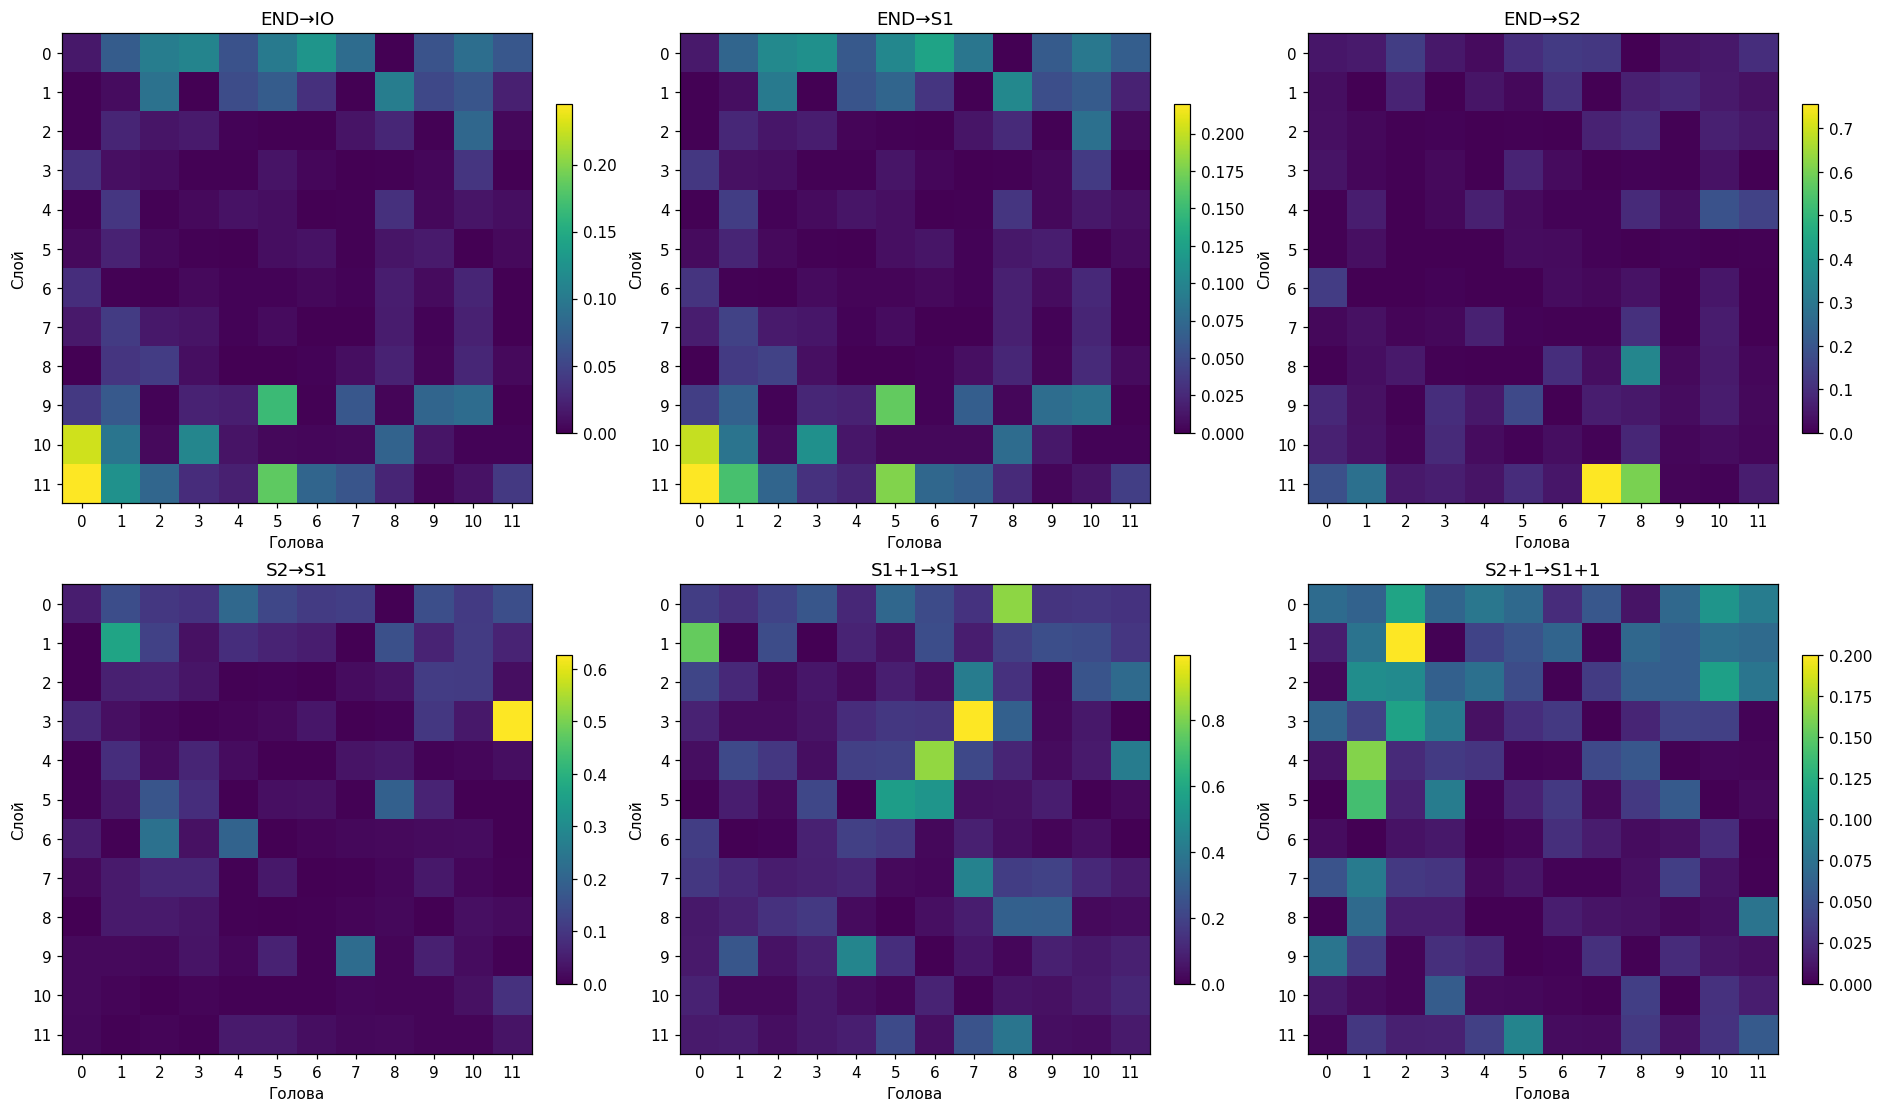

Лидеры внимания к повтору (S2→S1):


,layer,head,END→IO,END→S1,END→S2,S2→S1,S1+1→S1,S2+1→S1+1
47,3,11,0.000,0.000,0.000,0.627,0.000,0.002
13,1,1,0.008,0.008,0.000,0.366,0.005,0.077
74,6,2,0.000,0.000,0.000,0.233,0.010,0.010
115,9,7,0.067,0.066,0.059,0.222,0.059,0.028
4,0,4,0.062,0.062,0.022,0.212,0.111,0.080
76,6,4,0.003,0.003,0.000,0.201,0.188,0.001
68,5,8,0.014,0.014,0.003,0.193,0.044,0.033
62,5,2,0.005,0.005,0.002,0.164,0.027,0.019


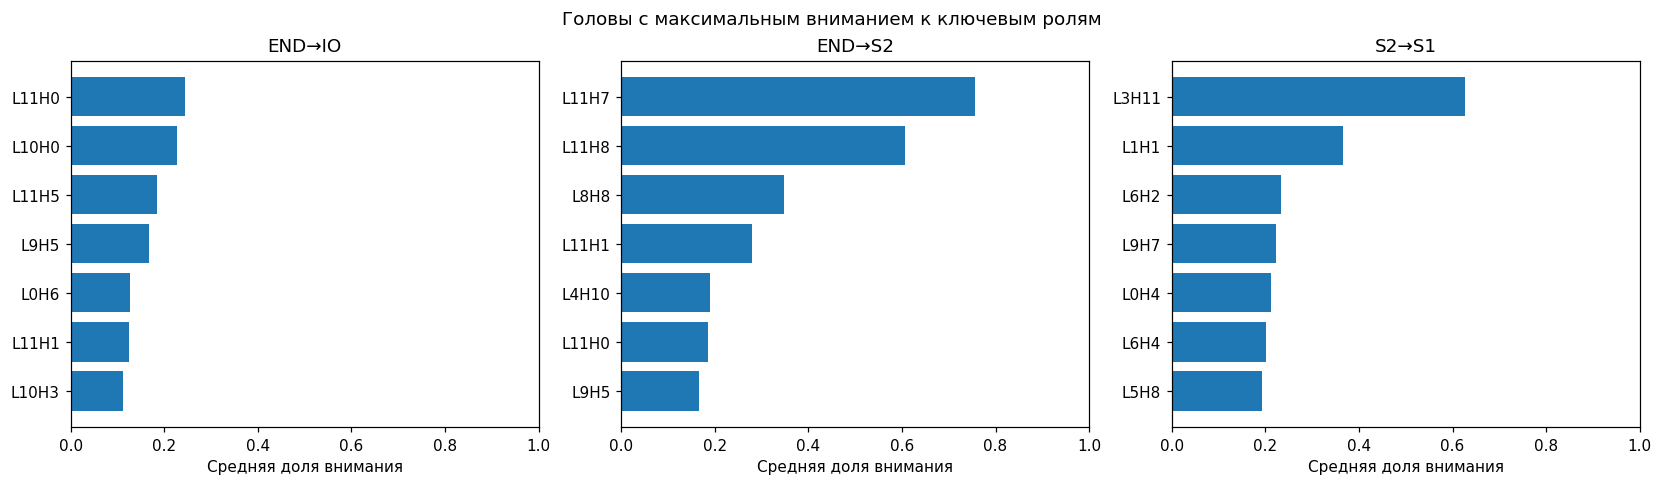

In [5]:
# Этап 2. Сканируем внимание всех 144 голов к заданным ролям.
ATTN_SPECS = [("END→IO", "END", "IO"), ("END→S1", "END", "S1"),
              ("END→S2", "END", "S2"), ("S2→S1", "S2", "S1"),
              ("S1+1→S1", "S1+1", "S1"), ("S2+1→S1+1", "S2+1", "S1+1")]
attn_all = np.zeros((len(scan_rows), len(ATTN_SPECS), 12, 12), np.float32)
for i, r in enumerate(tqdm(scan_rows, desc="Анализ attention")):
    pos = role_positions(r)
    tokens = to_ids(r["clean"])
    with torch.inference_mode():
        _, cache = model.run_with_cache(tokens, names_filter=lambda n: n.endswith(".attn.hook_pattern"))
    pattern = np.stack([cache[f"blocks.{l}.attn.hook_pattern"][0].float().cpu().numpy()
                        for l in range(12)])
    for j, (_, q, k) in enumerate(ATTN_SPECS):
        # Для S2 и IO с несколькими токенами используем последний токен запроса
        # и суммируем внимание по всем токенам источника.
        attn_all[i, j] = pattern[:, :, pos[q][-1], :][:, :, pos[k]].sum(axis=-1)
    del cache
attn_mean = attn_all.mean(axis=0)
fig, axs = plt.subplots(2, 3, figsize=(17, 10), constrained_layout=True)
for j, (title, _, _) in enumerate(ATTN_SPECS):
    ax = axs.flat[j]; im = ax.imshow(attn_mean[j], vmin=0, vmax=max(.01, attn_mean[j].max()))
    ax.set(title=title, xlabel="Голова", ylabel="Слой")
    ax.set_xticks(range(12)); ax.set_yticks(range(12))
    fig.colorbar(im, ax=ax, shrink=.7)
fig.savefig(OUT / "attention.png", dpi=170)
plt.show()

attn_summary = pd.DataFrame([
    {"layer":l, "head":h, **{ATTN_SPECS[j][0]:float(attn_mean[j,l,h]) for j in range(len(ATTN_SPECS))}}
    for l in range(12) for h in range(12)])
print("Лидеры внимания к повтору (S2→S1):")
display(attn_summary.nlargest(8, "S2→S1").round(3))

# Показываем лидеров для трёх разных предполагаемых функций, а не только общую карту.
roles_show = ["END→IO", "END→S2", "S2→S1"]
fig, axs = plt.subplots(1, 3, figsize=(15, 4.3), constrained_layout=True)
for ax, role_name in zip(axs, roles_show):
    candidates = attn_summary.nlargest(7, role_name).sort_values(role_name)
    labels = [f"L{int(l)}H{int(h)}" for l, h in zip(candidates["layer"], candidates["head"])]
    ax.barh(labels, candidates[role_name])
    ax.set(title=role_name, xlabel="Средняя доля внимания", xlim=(0, 1))
fig.suptitle("Головы с максимальным вниманием к ключевым ролям")
fig.savefig(OUT / "attention_leaders.png", dpi=180)
plt.show()

## 3. Activation patching: какие головы причинно меняют ответ?

Переносим активации отдельных голов из `clean` в `corrupted` и измеряем изменение `D`. Исследуем **все 144 головы**, причём отдельно на позициях `S2` и `END`. Перед сканированием проверяем *identity patch*: замена активации самой на себя не должна менять ответ.

На тепловых картах красный означает сдвиг `D` вверх, синий — вниз. **Знак эффекта не равен названию функции**: «отрицательный Name Mover» нельзя распознать только по синему цвету.

Identity END ошибка: 3e-06
Identity S2 ошибка: 3e-06
Контроли пройдены


Патчинг 144 голов:   0%|          | 0/16 [00:00<?, ?it/s]

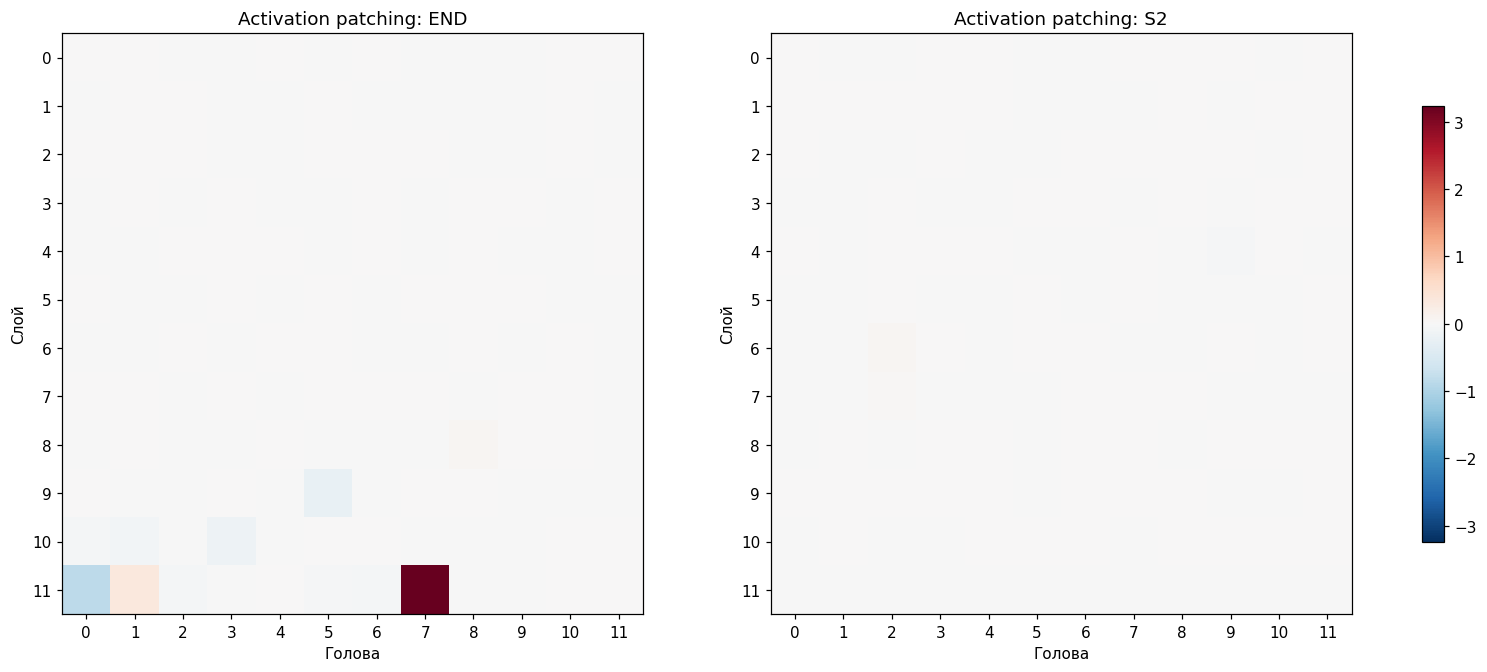

Топ причинных голов: END


,role,layer,head,head_id,effect,abs_effect,sign_fraction
139,END,11,7,L11H7,3.2337,3.2337,1.0000
132,END,11,0,L11H0,-0.8432,0.8432,0.0000
133,END,11,1,L11H1,0.3384,0.3384,1.0000
113,END,9,5,L9H5,-0.2509,0.2509,0.0000
123,END,10,3,L10H3,-0.1524,0.1524,0.0000
121,END,10,1,L10H1,-0.0841,0.0841,0.0625
120,END,10,0,L10H0,-0.0722,0.0722,0.0000
138,END,11,6,L11H6,-0.0607,0.0607,0.0000
134,END,11,2,L11H2,-0.0572,0.0572,0.0625
104,END,8,8,L8H8,0.0511,0.0511,1.0000


Топ причинных голов: S2


,role,layer,head,head_id,effect,abs_effect,sign_fraction
218,S2,6,2,L6H2,0.0679,0.0679,0.6250
201,S2,4,9,L4H9,-0.0390,0.0390,0.1250
230,S2,7,2,L7H2,0.0274,0.0274,0.5625
220,S2,6,4,L6H4,-0.0242,0.0242,0.3750
199,S2,4,7,L4H7,0.0204,0.0204,0.8750
202,S2,4,10,L4H10,0.0170,0.0170,0.7500
225,S2,6,9,L6H9,0.0127,0.0127,0.8750
193,S2,4,1,L4H1,-0.0118,0.0118,0.0625
191,S2,3,11,L3H11,0.0115,0.0115,0.5625
204,S2,5,0,L5H0,-0.0107,0.0107,0.4375


Отобрано проверок (роль, слой, голова): 12


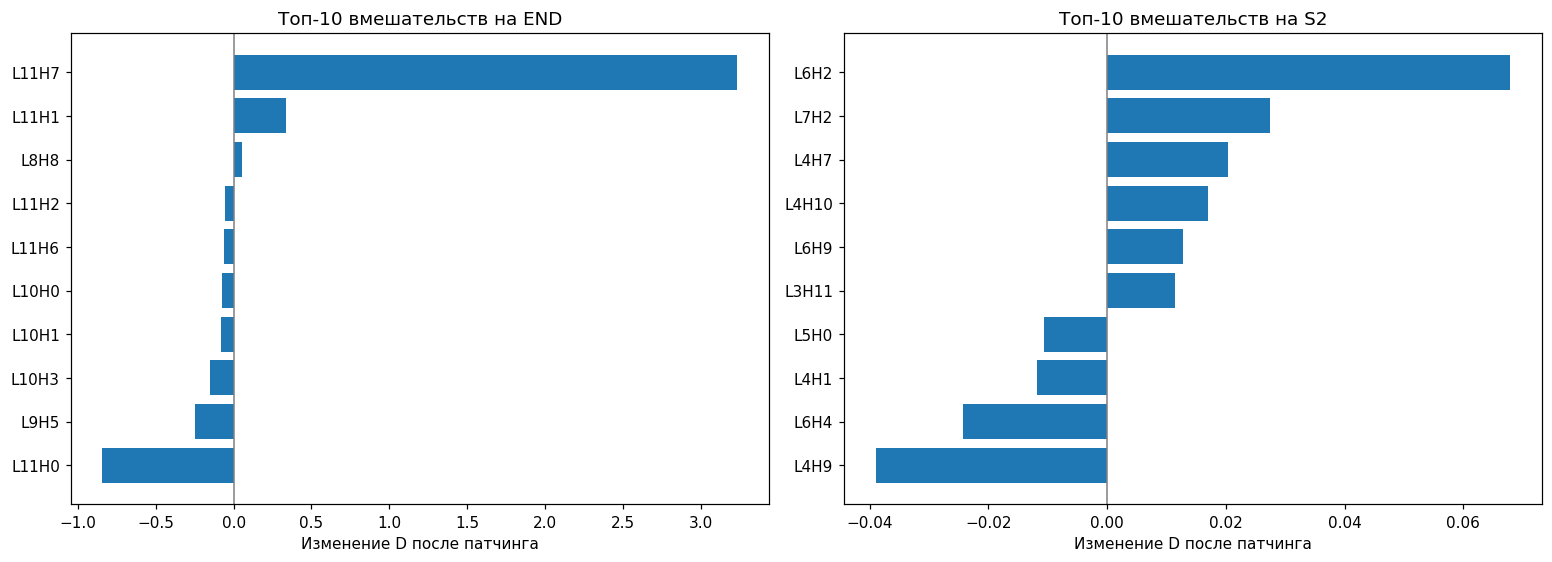

**Интерпретация:** сильная голова — кандидат на причинную роль, но назвать её Name Mover или S-Inhibition можно только после независимых функциональных тестов.

In [6]:
# Этап 3. Проводим identity-контроль и activation patching всех голов.
# Один элемент батча — одна проверяемая голова слоя; выход остальных не изменяется.
def cache_z(row, which):
    with torch.inference_mode():
        _, cache = model.run_with_cache(to_ids(row[which]),
                                       names_filter=lambda n: n.endswith(".attn.hook_z"))
    return [cache[f"blocks.{l}.attn.hook_z"][0].detach().clone() for l in range(12)]

def score_head_batch(row, which, candidate, layer, role, donors):
    pref = to_ids(row[which]); full = to_ids(row[which] + row[candidate])
    n = pref.shape[1]
    assert torch.equal(pref[0], full[0,:n])
    pos = role_positions(row, which)[role][-1]
    batch = full.repeat(N_HEADS, 1)
    called = [False]
    def patch(z, hook):
        called[0] = True
        z = z.clone()
        heads = torch.arange(N_HEADS, device=z.device)
        z[heads, pos, heads, :] = donors.to(z.device, z.dtype)
        return z
    with torch.inference_mode():
        logits = model.run_with_hooks(batch, fwd_hooks=[(f"blocks.{layer}.attn.hook_z", patch)])
    assert called[0], "Хук не выполнился"
    lp = torch.log_softmax(logits[:,n-1:-1].float(), -1)
    targets = full[:,n:].expand(N_HEADS, -1)
    return lp.gather(-1, targets.unsqueeze(-1)).squeeze(-1).sum(-1).float().cpu().numpy()

def patched_heads(row, layer, role, donors, which="corrupted"):
    return (score_head_batch(row, which, "correct", layer, role, donors)
          - score_head_batch(row, which, "wrong", layer, role, donors))

probe = scan_rows[0]
own = cache_z(probe,"corrupted")
for role in ("END","S2"):
    p = role_positions(probe,"corrupted")[role][-1]
    identity = patched_heads(probe, 11, role, own[11][p])
    error = float(np.max(np.abs(identity - D(probe,"corrupted"))))
    print("Identity", role, "ошибка:", round(error, 6))
    assert error < 0.03, "Патчинг некорректен: проверьте модель/хуки"
print("Контроли пройдены")

# 8. Причинное сканирование после identity-контроля.
# 8. Основной причинный скан и тепловые карты эффектов.
PATCH_ROLES = ["END","S2"]
patch_effects = np.zeros((2, len(scan_rows), 12, 12), np.float32)
for i,r in enumerate(tqdm(scan_rows, desc="Патчинг 144 голов")):
    donor = cache_z(r, "clean")
    baseline = D(r, "corrupted")
    pos = role_positions(r, "clean")
    for j,role in enumerate(PATCH_ROLES):
        for layer in range(12):
            d = patched_heads(r, layer, role, donor[layer][pos[role][-1]])
            patch_effects[j,i,layer,:] = d - baseline
avg_effect = patch_effects.mean(axis=1)
fig, axs = plt.subplots(1,2,figsize=(14,6),constrained_layout=True)
lim = max(.001, np.max(np.abs(avg_effect)))
for j,role in enumerate(PATCH_ROLES):
    im=axs[j].imshow(avg_effect[j],cmap="RdBu_r",vmin=-lim,vmax=lim)
    axs[j].set(title=f"Activation patching: {role}",xlabel="Голова",ylabel="Слой")
    axs[j].set_xticks(range(12)); axs[j].set_yticks(range(12))
fig.colorbar(im,ax=list(axs),shrink=.75)
fig.savefig(OUT/"activation_patching.png",dpi=180)
plt.show()
rank = pd.DataFrame([
    {"role":role,"layer":l,"head":h,"head_id":f"L{l}H{h}",
     "effect":float(avg_effect[j,l,h]),"abs_effect":float(abs(avg_effect[j,l,h])),
     "sign_fraction":float((patch_effects[j,:,l,h]>0).mean())}
    for j,role in enumerate(PATCH_ROLES) for l in range(12) for h in range(12)
]).sort_values("abs_effect",ascending=False)
rank.to_csv(OUT/"head_screen.csv",index=False)
for role in PATCH_ROLES:
    print("Топ причинных голов:",role)
    display(rank[rank.role==role].head(12).round(4))
# Отбор определяется ТОЛЬКО поисковой выборкой.
selected = []
for role in PATCH_ROLES:
    selected.extend((role,int(x.layer),int(x.head)) for x in rank[rank.role==role].head(TOP_PER_POSITION).itertuples())
selected = list(dict.fromkeys(selected))
print("Отобрано проверок (роль, слой, голова):",len(selected))

# Сравнение причинного влияния: позиции END и S2 на единой шкале эффекта.
fig, axs = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
for ax, role_name in zip(axs, PATCH_ROLES):
    part = rank[rank.role == role_name].head(10).sort_values("effect")
    ax.barh(part["head_id"], part["effect"])
    ax.axvline(0, color="gray", linewidth=1)
    ax.set(title=f"Топ-10 вмешательств на {role_name}", xlabel="Изменение D после патчинга")
fig.savefig(OUT / "causal_head_ranking.png", dpi=180)
plt.show()
display(Markdown("**Интерпретация:** сильная голова — кандидат на причинную роль, но назвать её "
                 "Name Mover или S-Inhibition можно только после независимых функциональных тестов."))

## 4. Проверка обобщения и mean ablation

Отобранные на поисковой выборке головы проверяем на **других парах имён**. Отдельно используем *mean ablation*: вместо активации головы подставляем среднее по калибровочным примерам. Если оба эксперимента согласуются, причинная гипотеза становится сильнее.

На диаграммах сопоставляем **эффект при переносе** и **эффект при замене средним**. У них необязательно одинаковый знак: это разные вмешательства, поэтому результат не следует интерпретировать как «два измерения одной величины».

Валидация кандидатов:   0%|          | 0/16 [00:00<?, ?it/s]

,role,layer,head,head_id,mean,pair_std,sign_fraction,abs_mean
5,END,11,7,L11H7,2.895,0.894,1.0,2.895
3,END,11,0,L11H0,-0.752,0.194,0.0,0.752
4,END,11,1,L11H1,0.310,0.056,1.0,0.310
0,END,9,5,L9H5,-0.177,0.086,0.0,0.177
2,END,10,3,L10H3,-0.168,0.016,0.0,0.168
1,END,10,1,L10H1,-0.074,0.012,0.0,0.074
9,S2,6,2,L6H2,0.063,0.003,1.0,0.063
7,S2,4,9,L4H9,-0.031,0.014,0.0,0.031
6,S2,4,7,L4H7,0.031,0.004,1.0,0.031
10,S2,6,4,L6H4,-0.028,0.009,0.0,0.028


Калибровка средних активаций:   0%|          | 0/12 [00:00<?, ?it/s]

Mean ablation:   0%|          | 0/12 [00:00<?, ?it/s]

Причинный патчинг и mean ablation (знак может различаться):


,role,layer,head,head_id,mean,pair_std,sign_fraction,abs_mean,mean_ablation,std
0,END,11,7,L11H7,2.895,0.894,1.0,2.895,-1.543,0.518
1,END,11,0,L11H0,-0.752,0.194,0.0,0.752,0.468,0.612
2,END,11,1,L11H1,0.310,0.056,1.0,0.310,-0.162,0.202
3,END,9,5,L9H5,-0.177,0.086,0.0,0.177,0.079,0.130
4,END,10,3,L10H3,-0.168,0.016,0.0,0.168,0.100,0.255
5,END,10,1,L10H1,-0.074,0.012,0.0,0.074,-0.045,0.218
6,S2,6,2,L6H2,0.063,0.003,1.0,0.063,-0.015,0.031
7,S2,4,9,L4H9,-0.031,0.014,0.0,0.031,0.025,0.019
8,S2,4,7,L4H7,0.031,0.004,1.0,0.031,-0.023,0.035
9,S2,6,4,L6H4,-0.028,0.009,0.0,0.028,0.031,0.029


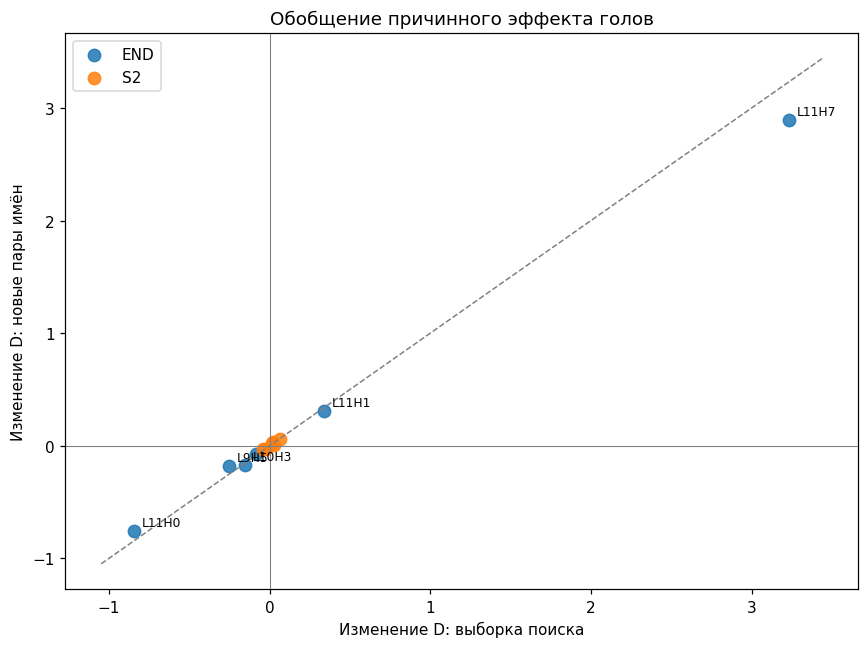

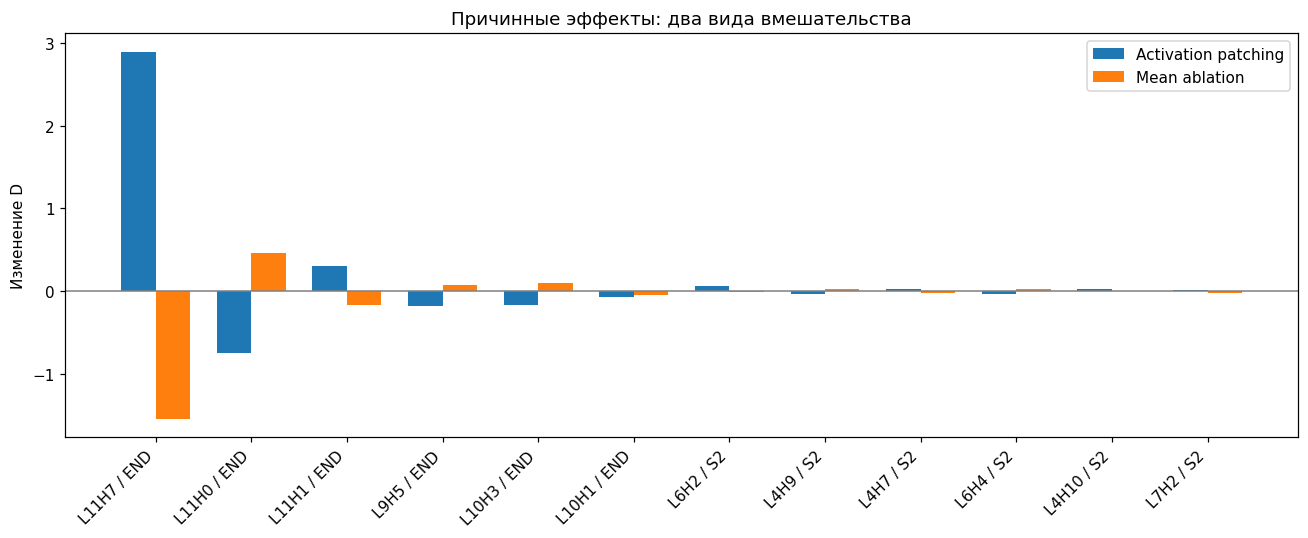

In [7]:
# Этап 4. Валидируем головы и выполняем mean ablation.
# Полный повтор скана здесь не нужен: проверяем только заранее выбранные компоненты.
def scalar_head_patch(row, which, candidate, layer, head, role, vector):
    pos = role_positions(row, which)[role][-1]
    def edit(z, hook):
        z=z.clone(); z[0,pos,head,:]=vector.to(z.device,z.dtype); return z
    return candidate_score(row, which, candidate, [(f"blocks.{layer}.attn.hook_z",edit)])
def head_margin(row, which, layer, head, role, vector):
    return (scalar_head_patch(row,which,"correct",layer,head,role,vector)
          - scalar_head_patch(row,which,"wrong",layer,head,role,vector))

v_records=[]
for r in tqdm(validation,desc="Валидация кандидатов"):
    donor=cache_z(r,"clean"); pos=role_positions(r,"clean"); baseline=D(r,"corrupted")
    for role,l,h in selected:
        d=head_margin(r,"corrupted",l,h,role,donor[l][pos[role][-1],h,:])
        v_records.append(dict(pair_id=r["pair_id"],role=role,layer=l,head=h,head_id=f"L{l}H{h}",effect=d-baseline))
validation_df=pd.DataFrame(v_records)
# Парный эффект: сначала среднее внутри пары имён, потом между парами.
pair_validation=validation_df.groupby(["pair_id","role","layer","head","head_id"],as_index=False).effect.mean()
validated=(pair_validation.groupby(["role","layer","head","head_id"],as_index=False)
           .agg(mean=("effect","mean"),pair_std=("effect","std"),
                sign_fraction=("effect",lambda x: float((x>0).mean()))))
validated["abs_mean"]=validated["mean"].abs()
validated=validated.sort_values("abs_mean",ascending=False)
validation_df.to_csv(OUT/"head_validation.csv",index=False)
display(validated.head(20).round(3))

# 10. Независимая mean ablation найденных голов.
# 10. Mean ablation как независимый контроль: подставляем средние активации из отдельных фраз.
# Средние вычисляются по калибровочным текстам, а не по финальной выборке.
calibration_rows = discovery[-min(12,len(discovery)):]
mean_vectors={role:[[] for _ in range(12)] for role in PATCH_ROLES}
for r in tqdm(calibration_rows,desc="Калибровка средних активаций"):
    z=cache_z(r,"clean"); pos=role_positions(r,"clean")
    for role in PATCH_ROLES:
        for l in range(12):
            mean_vectors[role][l].append(z[l][pos[role][-1]].detach().float().cpu())
mean_vectors={role:[torch.stack(samples).mean(0) for samples in per_layer]
              for role,per_layer in mean_vectors.items()}
mean_records=[]
for r in tqdm(validation[:min(12,len(validation))],desc="Mean ablation"):
    baseline=D(r,"clean")
    for role,l,h in selected:
        value=mean_vectors[role][l][h]
        patched=head_margin(r,"clean",l,h,role,value)
        mean_records.append(dict(role=role,layer=l,head=h,head_id=f"L{l}H{h}",pair_id=r["pair_id"],
                                 effect=patched-baseline))
mean_df=pd.DataFrame(mean_records)
mean_summary=(mean_df.groupby(["role","layer","head","head_id"],as_index=False)
              .agg(mean_ablation=("effect","mean"),std=("effect","std")))
head_evidence=validated.merge(mean_summary,on=["role","layer","head","head_id"],how="left")
print("Причинный патчинг и mean ablation (знак может различаться):")
display(head_evidence.head(18).round(3))

# Диаграмма: насколько причинные эффекты сохраняются на других именах.
screen_vs_val = validated.merge(
    rank[["role", "layer", "head", "effect"]], on=["role", "layer", "head"], how="left"
).rename(columns={"effect": "screen_effect"})
fig, ax = plt.subplots(figsize=(8, 6))
for role_name, part in screen_vs_val.groupby("role"):
    ax.scatter(part["screen_effect"], part["mean"], s=65, alpha=.85, label=role_name)
    for row in part.itertuples():
        if abs(row.mean) >= 0.15 or abs(row.screen_effect) >= 0.15:
            ax.annotate(row.head_id, (row.screen_effect, row.mean), xytext=(5, 3),
                        textcoords="offset points", fontsize=8)
limits = np.r_[screen_vs_val["screen_effect"].to_numpy(), screen_vs_val["mean"].to_numpy()]
lo, hi = float(np.min(limits)), float(np.max(limits))
margin = max(.1, .05 * (hi - lo))
ax.plot([lo-margin, hi+margin], [lo-margin, hi+margin], linestyle="--", color="gray", linewidth=1)
ax.axhline(0, color="gray", linewidth=.7); ax.axvline(0, color="gray", linewidth=.7)
ax.set(xlabel="Изменение D: выборка поиска", ylabel="Изменение D: новые пары имён",
       title="Обобщение причинного эффекта голов")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "screen_vs_validation.png", dpi=180)
plt.show()

# Сопоставление двух РАЗНЫХ вмешательств для обнаруженных голов.
show_evidence = head_evidence.head(12).copy()
show_evidence["Голова и позиция"] = show_evidence["head_id"] + " / " + show_evidence["role"]
fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(show_evidence))
ax.bar(x - .18, show_evidence["mean"], width=.36, label="Activation patching")
ax.bar(x + .18, show_evidence["mean_ablation"], width=.36, label="Mean ablation")
ax.axhline(0, linewidth=1, color="gray")
ax.set_xticks(x, show_evidence["Голова и позиция"], rotation=45, ha="right")
ax.set(ylabel="Изменение D", title="Причинные эффекты: два вида вмешательства")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "patching_vs_mean_ablation.png", dpi=180)
plt.show()

## 5. Функциональные признаки и семь гипотез из статьи

Совмещаем attention, причинный эффект, вклад в **различающий токен имени** и управляемую маршрутизацию внимания. Затем проверяем кандидатов на *Duplicate Token, Previous Token, Induction, S-Inhibition, Name Mover, Negative Name Mover* и *Backup Name Mover*.

У каждой группы разные критерии. Например, Name Mover должен переносить информацию о получателе, а S-Inhibition — влиять на запросы поздних голов. **Таблица кандидатов — не доказательство семи групп**; выводы зависят от подтверждения причинных функций.

Логит-вклад:   0%|          | 0/12 [00:00<?, ?it/s]

Функции — пока кандидаты, не доказанные группы:


,role,layer,head,head_id,mean,pair_std,sign_fraction,abs_mean,mean_ablation,std,END→IO,END→S1,END→S2,S2→S1,S1+1→S1,S2+1→S1+1,recipient,subject,selectivity
0,END,11,7,L11H7,2.895,0.894,1.0,2.895,-1.543,0.518,0.065,0.067,0.757,0.013,0.254,0.006,0.558,-0.935,1.493
1,END,11,0,L11H0,-0.752,0.194,0.0,0.752,0.468,0.612,0.245,0.220,0.185,0.012,0.070,0.004,1.023,1.488,-0.465
2,END,11,1,L11H1,0.310,0.056,1.0,0.310,-0.162,0.202,0.124,0.156,0.280,0.004,0.077,0.032,0.055,-0.123,0.178
3,END,9,5,L9H5,-0.177,0.086,0.0,0.177,0.079,0.130,0.167,0.167,0.166,0.060,0.130,0.001,0.288,0.331,-0.043
4,END,10,3,L10H3,-0.168,0.016,0.0,0.168,0.100,0.255,0.112,0.110,0.091,0.010,0.064,0.059,0.196,0.301,-0.105
5,END,10,1,L10H1,-0.074,0.012,0.0,0.074,-0.045,0.218,0.095,0.084,0.036,0.008,0.021,0.006,0.173,0.097,0.076
6,S2,6,2,L6H2,0.063,0.003,1.0,0.063,-0.015,0.031,0.000,0.000,0.000,0.233,0.010,0.010,-0.059,-0.074,0.015
7,S2,4,9,L4H9,-0.031,0.014,0.0,0.031,0.025,0.019,0.005,0.005,0.027,0.007,0.029,0.001,-0.147,-0.130,-0.017
8,S2,4,7,L4H7,0.031,0.004,1.0,0.031,-0.023,0.035,0.002,0.002,0.009,0.034,0.217,0.044,0.019,0.024,-0.005
9,S2,6,4,L6H4,-0.028,0.009,0.0,0.028,0.031,0.029,0.003,0.003,0.000,0.201,0.188,0.001,-0.035,-0.052,0.018


Тест маршрутизации:   0%|          | 0/8 [00:00<?, ?it/s]

Управляемое внимание: эффект на разницу полных logP


force_IO  force_S2
layer head                    
4     7       -0.084     0.059
      9        0.029    -0.025
      10       0.034     0.015
6     2        0.402    -0.128
      4       -0.024    -0.019
7     2       -0.085    -0.045
9     5        0.718    -0.545
10    1        2.227    -2.022
      3        1.736    -1.262
11    0        4.119    -2.648
      1       -0.863     0.308
      7       -4.383     0.708

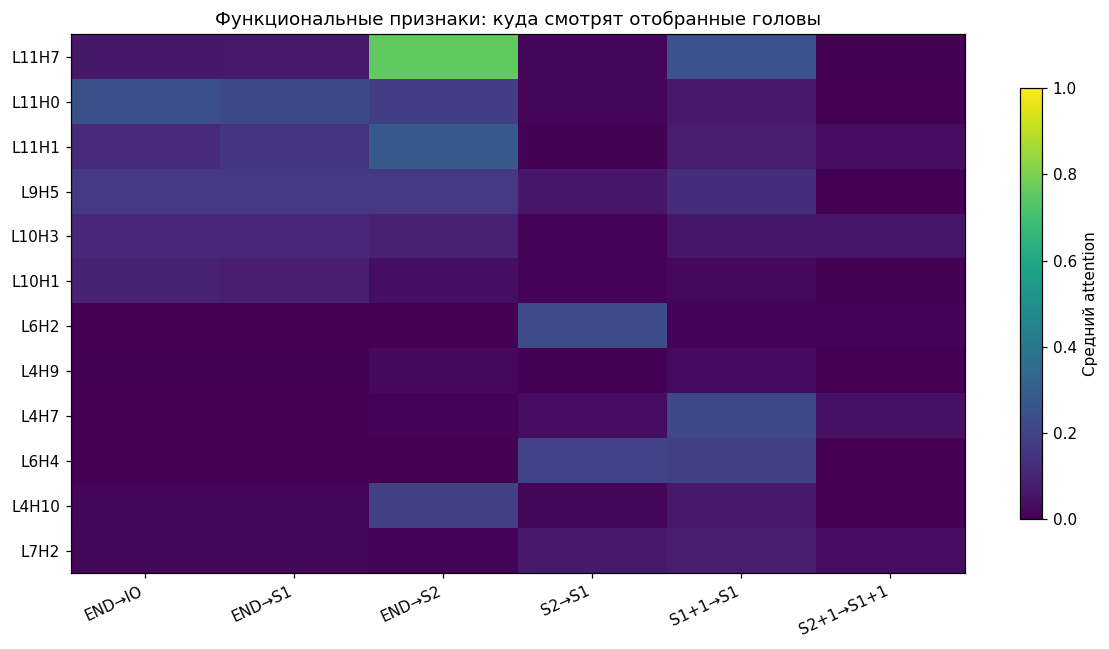

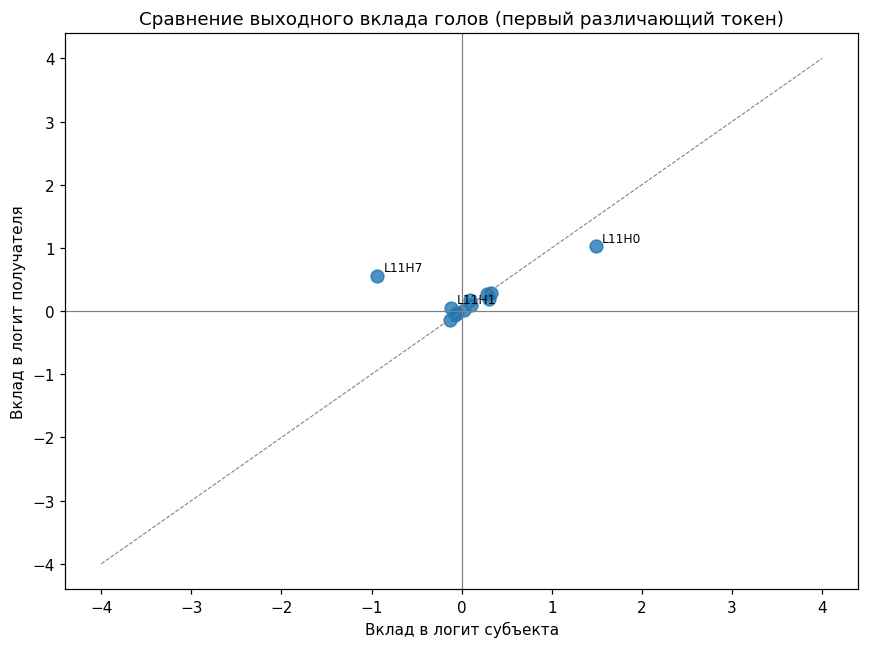

In [8]:
# Этап 5. Измеряем функциональные признаки и маршрутизацию внимания.
# На дополнительной диагностике не вводим новые метки функций автоматически.
head_evidence=head_evidence.merge(attn_summary,on=["layer","head"],how="left")

def decision_tokens(row):
    # Находим первую ПОЗИЦИЮ различия токенов имён после общего префикса.
    # Так анализ остаётся информативным, даже если имена имеют общий первый токен.
    prefix=to_ids(row["clean"]); n=prefix.shape[1]
    right=to_ids(row["clean"]+row["correct"])[0,n:].tolist()
    wrong=to_ids(row["clean"]+row["wrong"])[0,n:].tolist()
    differences=[j for j,(a,b) in enumerate(zip(right,wrong)) if a!=b]
    if not differences: return None
    j=differences[0]
    shared=torch.tensor(right[:j],device=DEVICE,dtype=prefix.dtype)[None,:]
    return torch.cat([prefix,shared],dim=1),right[j],wrong[j]

def next_logits_ablate(tokens,layer,head,zero=False):
    if not zero:
        with torch.inference_mode(): logits=model(tokens)
    else:
        def edit(z,hook):
            z=z.clone(); z[0,-1,head,:]=0; return z
        with torch.inference_mode():
            logits=model.run_with_hooks(tokens,fwd_hooks=[(f"blocks.{layer}.attn.hook_z",edit)])
    return logits[0,-1].detach().float().cpu()

# Выбираем до 14 уникальных голов; проверяем первый РАЗЛИЧАЮЩИЙ токен имён.
head_list=list(dict.fromkeys((int(r.layer),int(r.head)) for r in head_evidence.head(14).itertuples()))
logit_features=[]
for row in tqdm(validation[:min(12,len(validation))],desc="Логит-вклад"):
    decision=decision_tokens(row)
    if decision is None: continue
    tokens,c,w=decision
    raw=next_logits_ablate(tokens,0,0,False)
    for l,h in head_list:
        ablated=next_logits_ablate(tokens,l,h,True)
        delta=raw-ablated
        delta=delta-delta.mean()
        logit_features.append(dict(layer=l,head=h,recipient=float(delta[c]),subject=float(delta[w]),
                                   selectivity=float(delta[c]-delta[w])))
logit_df=pd.DataFrame(logit_features)
if not logit_df.empty:
    diagnostic=logit_df.groupby(["layer","head"],as_index=False)[["recipient","subject","selectivity"]].mean()
    head_evidence=head_evidence.merge(diagnostic,on=["layer","head"],how="left")
print("Функции — пока кандидаты, не доказанные группы:")
display(head_evidence.head(16).round(3))

# 12. Управляемое внимание: проверка маршрутизации к IO и S2.
# 12. Проверка маршрутизации: заставляем выбранную голову читать IO или S2.
# Это НЕ OV copy score оригинальной статьи: это управляемый тест attention routing.
route_records=[]
for r in tqdm(validation[:min(8,len(validation))],desc="Тест маршрутизации"):
    pos=role_positions(r,"clean"); original=D(r,"clean")
    for l,h in head_list:
        for target in ("IO","S2"):
            target_positions=pos[target]
            def forced_pattern(pattern,hook):
                p=pattern.clone()
                # END — последняя позиция промпта, а не полного текста с ответом.
                end=pos["END"][-1]
                p[0,h,end,:]=0
                p[0,h,end,target_positions]=1.0/len(target_positions)
                return p
            hook=[(f"blocks.{l}.attn.hook_pattern",forced_pattern)]
            d=D(r,"clean",hook)
            route_records.append(dict(layer=l,head=h,target=target,effect=d-original))
route_df=pd.DataFrame(route_records)
route_summary=route_df.pivot_table(index=["layer","head"],columns="target",values="effect",aggfunc="mean")
route_summary.columns=["force_"+c for c in route_summary.columns]
head_evidence=head_evidence.merge(route_summary.reset_index(),on=["layer","head"],how="left")
print("Управляемое внимание: эффект на разницу полных logP")
display(route_summary.round(3))
# Сохраняем диагностические данные для дальнейшей аргументации.
head_evidence.to_csv(OUT/"functional_evidence.csv",index=False)

# Визуальный «отпечаток» функциональных признаков отобранных голов.
role_cols = ["END→IO", "END→S1", "END→S2", "S2→S1", "S1+1→S1", "S2+1→S1+1"]
feat_view = head_evidence.drop_duplicates(["layer", "head"]).head(12).copy()
feat_view["Подпись"] = [f"L{l}H{h}" for l, h in zip(feat_view["layer"], feat_view["head"])]
values = feat_view[role_cols].fillna(0).to_numpy()
fig, ax = plt.subplots(figsize=(11, 6))
im = ax.imshow(values, cmap="viridis", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(role_cols)), role_cols, rotation=25, ha="right")
ax.set_yticks(range(len(feat_view)), feat_view["Подпись"])
ax.set_title("Функциональные признаки: куда смотрят отобранные головы")
fig.colorbar(im, ax=ax, label="Средний attention", shrink=.8)
fig.tight_layout()
fig.savefig(OUT / "functional_attention_profiles.png", dpi=180)
plt.show()

# Отдельная проверка того, усиливают ли головы получателя или субъекта.
if "selectivity" in head_evidence.columns:
    subset = head_evidence.dropna(subset=["recipient", "subject"]).copy()
    if not subset.empty:
        fig, ax = plt.subplots(figsize=(8, 6))
        ax.scatter(subset["subject"], subset["recipient"], s=70, alpha=.8)
        for row in subset.itertuples():
            if abs(row.selectivity) >= .15:
                ax.annotate(row.head_id, (row.subject, row.recipient), xytext=(4, 3),
                            textcoords="offset points", fontsize=8)
        ax.axhline(0, color="gray", linewidth=.8)
        ax.axvline(0, color="gray", linewidth=.8)
        ax.plot([-4, 4], [-4, 4], linestyle="--", color="gray", linewidth=.7)
        ax.set(xlabel="Вклад в логит субъекта", ylabel="Вклад в логит получателя",
               title="Сравнение выходного вклада голов (первый различающий токен)")
        fig.tight_layout()
        fig.savefig(OUT / "logit_contributions.png", dpi=180)
        plt.show()

In [9]:
# Этап 5. Проверяем кандидатов на семь функций из исходной статьи.
# Пороговые эвристики служат для отбора, но не «доказывают» функции.
# Name Mover: внимание к IO + полезное вмешательство/маршрутизация.
# Negative Name Mover: внимание к именам + вредная selectivity, не просто отрицательный patch.
# Duplicate: S2→S1; Previous: S1+1→S1; Induction: S2+1→S1+1.
# S-Inhibition требует патчинга Q поздних голов; Backup — отключения основных.
feature=head_evidence.drop_duplicates(["layer","head"]).copy()

def show_candidates(label,score_col,descending=True,min_value=None):
    part=feature.dropna(subset=[score_col]).sort_values(score_col,ascending=not descending)
    if min_value is not None and descending: part=part[part[score_col]>=min_value]
    print(label, "— кандидаты, не окончательные группы")
    display(part[["head_id", "layer", "head",score_col,"mean","mean_ablation"]].head(8).round(3))

# Позиционные кандидаты ищем СРЕДИ ВСЕХ 144 голов, а не только среди
# сильных по END/S2. Иначе Previous и Induction будут отобраны неправильно.
for label, attention_key in [
    ("Duplicate Token", "S2→S1"),
    ("Previous Token", "S1+1→S1"),
    ("Induction", "S2+1→S1+1")
]:
    print("\nAttention-кандидаты:", label)
    display(attn_summary.nlargest(6,attention_key)[["layer","head",attention_key]].round(3))
    # Проверяем причинное изменение на соответствующей позиции в новых примерах.
    test_role={"Duplicate Token":"S2", "Previous Token":"S1+1", "Induction":"S2+1"}[label]
    test = attn_summary.nlargest(3,attention_key)
    effects=[]
    for ex in validation[:min(6,len(validation))]:
        donor=cache_z(ex,"clean"); p=role_positions(ex,"clean")[test_role][-1]
        baseline=D(ex,"corrupted")
        for candidate in test.itertuples():
            l,h=int(candidate.layer),int(candidate.head)
            new=head_margin(ex,"corrupted",l,h,test_role,donor[l][p,h])
            effects.append(dict(group=label,role=test_role,head=f"L{l}H{h}",effect=new-baseline))
    display(pd.DataFrame(effects).groupby(["group","head"]).effect.agg(["mean","std"]).round(3))
show_candidates("Внимание к IO", "END→IO")
if "selectivity" in feature: show_candidates("Поддержка IO в логитах", "selectivity")

# Отбираем несколько поздних получателей по ВАЛИДИРОВАННОМУ эффекту END.
late=(validated[(validated.role=="END") & (validated.layer>=7)]
      .sort_values("abs_mean",ascending=False).head(3))
# Ранние отправители: по патчингу на S2 и по устойчивому S2→S1.
early=(validated[(validated.role=="S2") & (validated.layer<9)]
       .sort_values("abs_mean",ascending=False).head(3))
receivers=[(int(r.layer),int(r.head)) for r in late.itertuples()]
senders=[(int(r.layer),int(r.head),"S2") for r in early.itertuples()]
if not senders: senders=[(3,11,"S2"),(6,2,"S2")]
assert receivers, "Нет поздних получателей — гипотеза позднего circuit не поддержана"
print("Отправители:",senders,"Получатели:",receivers)

# Диагностика Backup: сравниваем цену выключения альтернативной головы
# до и после выключения основного позднего компонента.
main_head=receivers[0]
alternatives=[h for h in receivers[1:] if h!=main_head]
def zero_heads_effect(row, removed):
    hooks=[]
    for l in sorted({l for l,h in removed}):
        heads=[h for ll,h in removed if ll==l]
        def zero(z,hook,heads=heads):
            z=z.clone(); z[0,role_positions(row,"clean")["END"][-1],heads,:]=0
            return z
        hooks.append((f"blocks.{l}.attn.hook_z",zero))
    return D(row,"clean",hooks)
backup=[]
for r in validation[:min(6,len(validation))]:
    full=D(r,"clean")
    no_main=zero_heads_effect(r,{main_head})
    for alt in alternatives:
        only_alt=zero_heads_effect(r,{alt})
        no_both=zero_heads_effect(r,{main_head,alt})
        backup.append(dict(candidate=f"L{alt[0]}H{alt[1]}",
                           interaction=(no_both-no_main)-(only_alt-full)))
if backup:
    print("Проверка Backup — взаимодействие отключений (не окончательное доказательство):")
    display(pd.DataFrame(backup).groupby("candidate").interaction.agg(["mean","std"]).round(3))

# Показываем семь исследуемых гипотез, но не объявляем их найденными.
from IPython.display import Markdown
hypotheses = pd.DataFrame([
    ("Duplicate Token", "Сопоставление второго имени с первым", "Attention S2→S1 + причинный тест"),
    ("Previous Token", "Передача информации о предыдущем токене", "Attention S1+1→S1 + причинный тест"),
    ("Induction", "Продолжение обнаруженного ранее паттерна", "Attention S2+1→S1+1 + причинный тест"),
    ("S-Inhibition", "Влияние субъекта на Q поздних голов", "Изолированный Q-path"),
    ("Name Mover", "Поддержка копирования/генерации получателя", "Attention IO + вклад в логиты/OV"),
    ("Negative Name Mover", "Противоположный эффект при чтении имён", "Вклад в логиты + ablation"),
    ("Backup Name Mover", "Компенсация после отключения основных голов", "Совместная ablation"),
], columns=["Функциональная гипотеза", "Искомая функция", "Необходимое подтверждение"])
display(hypotheses)
display(Markdown("**Статус:** таблица задаёт критерии проверки по мотивам исходной статьи. "
                 "Отнесение конкретных голов к семи группам пока остаётся гипотезой."))


Attention-кандидаты: Duplicate Token


,layer,head,S2→S1
47,3,11,0.627
13,1,1,0.366
74,6,2,0.233
115,9,7,0.222
4,0,4,0.212
76,6,4,0.201


mean    std
group           head               
Duplicate Token L1H1   0.004  0.024
                L3H11 -0.005  0.065
                L6H2   0.058  0.065


Attention-кандидаты: Previous Token


,layer,head,S1+1→S1
43,3,7,1.000
54,4,6,0.838
8,0,8,0.831
12,1,0,0.763
65,5,5,0.555
66,5,6,0.521


...

,head_id,layer,head,selectivity,mean,mean_ablation
0,L11H7,11,7,1.493,2.895,-1.543
2,L11H1,11,1,0.178,0.310,-0.162
5,L10H1,10,1,0.076,-0.074,-0.045
9,L6H4,6,4,0.018,-0.028,0.031
6,L6H2,6,2,0.015,0.063,-0.015
8,L4H7,4,7,-0.005,0.031,-0.023
11,L7H2,7,2,-0.009,0.012,-0.024
10,L4H10,4,10,-0.010,0.022,-0.002


Отправители: [(6, 2, 'S2'), (4, 9, 'S2'), (4, 7, 'S2')] Получатели: [(11, 7), (11, 0), (11, 1)]
Проверка Backup — взаимодействие отключений (не окончательное доказательство):


,mean,std
candidate,,
L11H0,-0.075,0.040
L11H1,0.054,0.022


,Функциональная гипотеза,Искомая функция,Необходимое подтверждение
0,Duplicate Token,Сопоставление второго имени с первым,Attention S2→S1 + причинный тест
1,Previous Token,Передача информации о предыдущем токене,Attention S1+1→S1 + причинный тест
2,Induction,Продолжение обнаруженного ранее паттерна,Attention S2+1→S1+1 + причинный тест
3,S-Inhibition,Влияние субъекта на Q поздних голов,Изолированный Q-path
4,Name Mover,Поддержка копирования/генерации получателя,Attention IO + вклад в логиты/OV
5,Negative Name Mover,Противоположный эффект при чтении имён,Вклад в логиты + ablation
6,Backup Name Mover,Компенсация после отключения основных голов,Совместная ablation


**Статус:** таблица задаёт критерии проверки по мотивам исходной статьи. Отнесение конкретных голов к семи группам пока остаётся гипотезой.

## 6. Path patching: какие компоненты передают информацию другим?

Проверяем пути от ранних голов-отправителей к поздним головам-получателям через `Q`, `K`, `V`. Другие выходы attention замораживаем относительно исходного прохода; собственные активации проверяем identity-контролем.

**Как читать:** ненулевой путь — свидетельство влияния через выбранный вход получателя в рамках данного вмешательства, **не доказательство всей многошаговой цепочки**. Малые значения и большие различия между примерами ограничивают вывод.

Identity path Q 0.0
Identity path K 0.0
Identity path V 0.0
Q/K/V path hooks доступны


Изолированные пути:   0%|          | 0/6 [00:00<?, ?it/s]

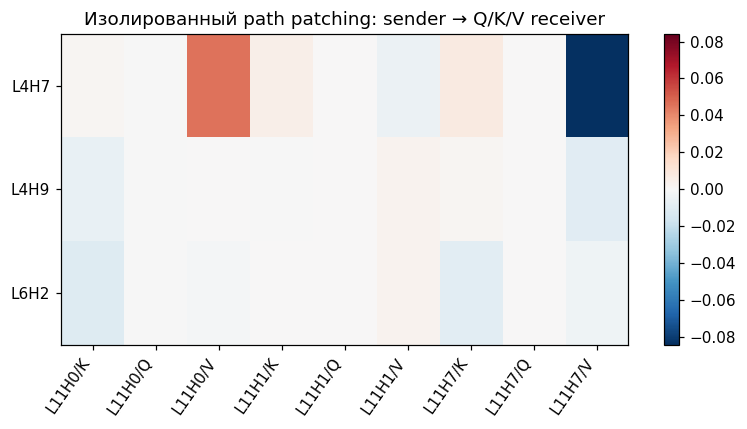

receiver,L11H0/K,L11H0/Q,L11H0/V,L11H1/K,L11H1/Q,L11H1/V,L11H7/K,L11H7/Q,L11H7/V
sender,,,,,,,,,
L4H7,0.0018,-0.0,0.0459,0.0049,0.0,-0.0049,0.0075,0.0,-0.0840
L4H9,-0.0063,-0.0,0.0001,-0.0006,0.0,0.0030,0.0020,0.0,-0.0093
L6H2,-0.0106,-0.0,-0.0017,0.0004,0.0,0.0031,-0.0091,0.0,-0.0034


Ненулевой путь — свидетельство влияния на выбранный вход, а не доказательство всей цепочки.


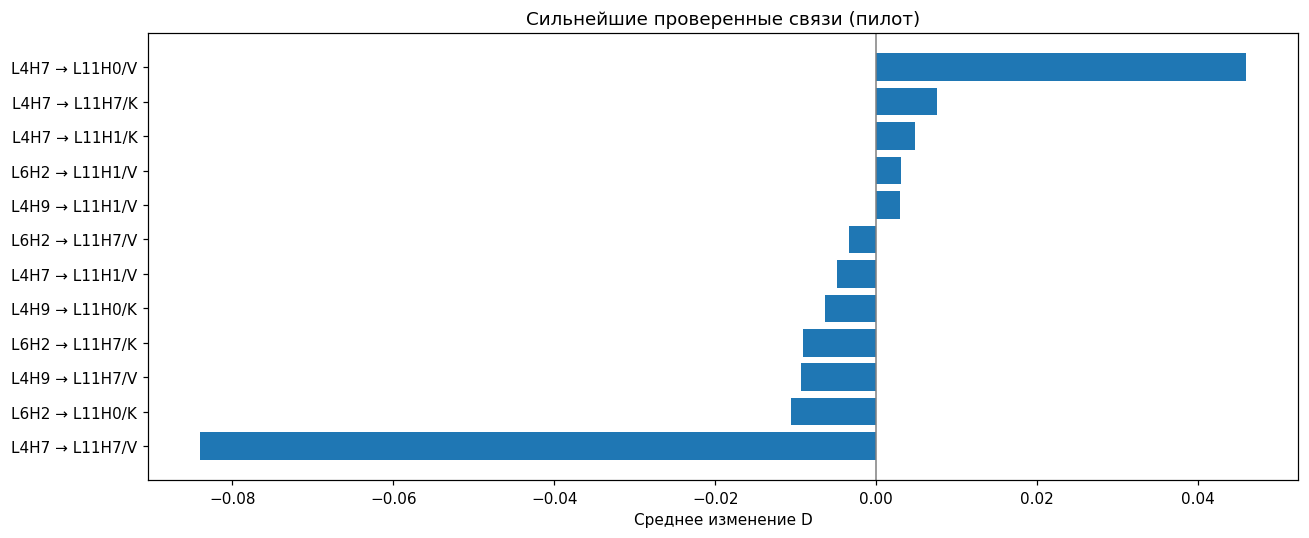

In [10]:
# Этап 6. Проводим изолированный path patching.
# Механизм: clean-cache, donor-cache, source-only+frozen-cache, receiver-only final run.
QKV={"Q": "q", "K": "k", "V": "v"}

def qkv_name(layer,component):
    return f"blocks.{layer}.attn.hook_{component.lower()}"

def frozen_capture(row,sender,receiver,component,identity=False):
    sl,sh,role=sender; rl,rh=receiver
    assert sl<rl, "Отправитель должен предшествовать получателю"
    tokens=to_ids(row["clean"])
    source_pos=role_positions(row,"clean")[role][-1]
    donor_pos=role_positions(row,"corrupted")[role][-1]
    clean_z=cache_z(row,"clean")
    donor_z=clean_z if identity else cache_z(row,"corrupted")
    captured={}
    hooks=[]
    for layer in range(12):
        baseline=clean_z[layer].detach()
        def freeze(z, hook, layer=layer, baseline=baseline):
            assert z.shape[1:]==baseline.shape
            output=baseline.unsqueeze(0).to(device=z.device,dtype=z.dtype).expand_as(z).clone()
            if layer==sl:
                vec=donor_z[layer][donor_pos,sh] if not identity else baseline[source_pos,sh]
                output[0,source_pos,sh,:]=vec.to(z.device,z.dtype)
            return output
        hooks.append((f"blocks.{layer}.attn.hook_z",freeze))
    def receiver_cache(value,hook):
        assert value.ndim==4 and value.shape[2]==N_HEADS
        captured["v"]=value[0,:,rh,:].detach().clone()
        return None
    hooks.append((qkv_name(rl,component), receiver_cache))
    with torch.inference_mode(): model.run_with_hooks(tokens,fwd_hooks=hooks)
    assert "v" in captured, f"Нет хука {qkv_name(rl,component)}"
    return captured["v"]

def receiver_path_margin(row,receiver,component,replacement):
    rl,rh=receiver
    end=role_positions(row,"clean")["END"][-1]
    def edit(value,hook):
        out=value.clone()
        if component=="Q":
            out[0,end,rh,:]=replacement[end].to(out.device,out.dtype)
        else:
            # K/V подменяем на всех позициях исходного префикса.
            out[0,:len(replacement),rh,:]=replacement.to(out.device,out.dtype)
        return out
    return D(row,"clean",[(qkv_name(rl,component),edit)])

# Обязательные контроли: замороженный запуск с собственным донором и self-patch.
probe=discovery[0]
# Для получателя берём ближайшего после отправителя.
cs=next((s for s in senders if any(s[0]<r[0] for r in receivers)),None)
assert cs is not None, "Не нашлось допустимого пути от ранних голов к поздним"
cr=next(r for r in receivers if cs[0]<r[0])
for component in ("Q","K","V"):
    vec=frozen_capture(probe,cs,cr,component,identity=True)
    err=abs(receiver_path_margin(probe,cr,component,vec)-D(probe,"clean"))
    print("Identity path",component,round(err,6))
    assert err<0.03, "Контроль path patching не пройден"
print("Q/K/V path hooks доступны")

# 16. Изолированный перебор путей между ранними и поздними головами.
# 16. Направленные причинные пути ранних голов к поздним: Q_END, K_all, V_all.
path_rows=discovery[:PATH_LIMIT]
path_records=[]
for r in tqdm(path_rows,desc="Изолированные пути"):
    baseline=D(r,"clean")
    for source in senders:
        for receiver in receivers:
            if source[0]>=receiver[0]: continue
            for comp in ("Q","K","V"):
                altered=frozen_capture(r,source,receiver,comp)
                effect=receiver_path_margin(r,receiver,comp,altered)-baseline
                path_records.append(dict(pair_id=r["pair_id"],sender=f"L{source[0]}H{source[1]}",
                                         receiver=f"L{receiver[0]}H{receiver[1]}/{comp}",effect=effect))
path_df=pd.DataFrame(path_records)
assert not path_df.empty
path_mean=path_df.pivot_table(index="sender",columns="receiver",values="effect",aggfunc="mean")
fig,ax=plt.subplots(figsize=(max(7,len(path_mean.columns)*.8),4))
lim=max(.001,float(np.abs(path_mean.to_numpy()).max()))
im=ax.imshow(path_mean.to_numpy(),cmap="RdBu_r",vmin=-lim,vmax=lim,aspect="auto")
ax.set_xticks(range(len(path_mean.columns)),path_mean.columns,rotation=55,ha="right")
ax.set_yticks(range(len(path_mean.index)),path_mean.index)
ax.set_title("Изолированный path patching: sender → Q/K/V receiver")
fig.colorbar(im,ax=ax)
plt.tight_layout(); fig.savefig(OUT/"path_patching.png",dpi=180); plt.show()
path_df.to_csv(OUT/"path_patching.csv",index=False)
display(path_mean.round(4))
print("Ненулевой путь — свидетельство влияния на выбранный вход, а не доказательство всей цепочки.")

# Рейтинг связей по модулю эффекта: небольшие значения должны быть видны явно.
edge_rank = (path_df.groupby(["sender", "receiver"], as_index=False)["effect"]
             .mean().assign(abs_effect=lambda x: x.effect.abs())
             .sort_values("abs_effect", ascending=False).head(12).sort_values("effect"))
fig, ax = plt.subplots(figsize=(12, 5))
labels = edge_rank["sender"] + " → " + edge_rank["receiver"]
ax.barh(labels, edge_rank["effect"])
ax.axvline(0, color="gray", linewidth=1)
ax.set(title="Сильнейшие проверенные связи (пилот)", xlabel="Среднее изменение D")
fig.tight_layout()
fig.savefig(OUT / "path_edges_ranked.png", dpi=180)
plt.show()

## 7. Проверка выделенного circuit и сопоставление с GPT-2 Small

Выделяем найденные головы, а остальные заменяем средними активациями. Сравниваем три режима: **полная модель**, **сохранённый circuit**, **все головы заменены средним**. Проверяем сначала на отложенных именах, затем **однократно** на финальных.

Коэффициент `R = (D_circuit − D_allmean) / (D_full − D_allmean)` показывает сохранение эффекта **только при этой конкретной mean ablation**. Значения ниже нуля означают, что выделенный набор оказался хуже контрольного режима; это не означает отсутствия какого-либо настоящего circuit. В оригинальном пользовательском отчёте GPT-2 Small приведено **85,1%** на одном шаблоне, но протоколы и метрики здесь различаются — **напрямую сравнивать проценты нельзя**.

Источники: [Wang et al. (2022)](https://arxiv.org/abs/2211.00593), исходный `IOI - study report(2).ipynb` и [TransformerLens](https://transformerlensorg.github.io/TransformerLens/content/compatibility_mode.html).

Средние активации для circuit:   0%|          | 0/12 [00:00<?, ?it/s]

Identity circuit: 0.0


Circuit validation:   0%|          | 0/16 [00:00<?, ?it/s]

validation голов сохранено 12 D full/circuit/allmean {'full': 0.722, 'circuit': -1.26, 'all_mean': 0.0} R -1.7454043822625065
При отрицательном/нестабильном знаменателе R нельзя интерпретировать как процент.


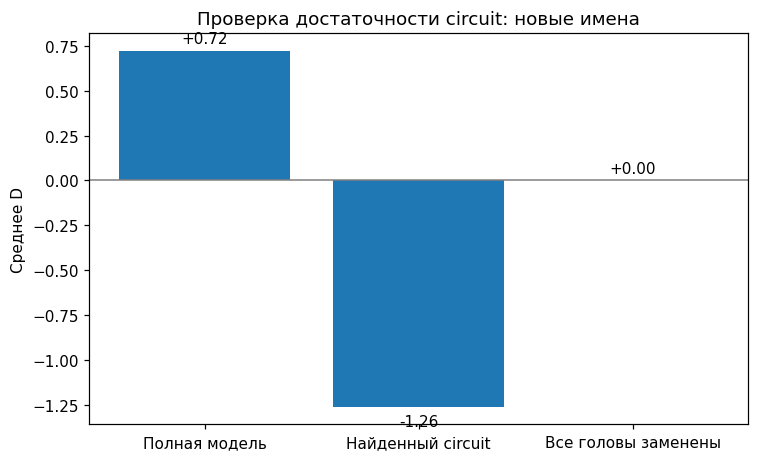

In [11]:
# Этап 7. Проверяем достаточность выделенного circuit.
# Это грубая position-agnostic mean ablation, а не дословная реплика
# групп и средних исходного GPT-2 исследования. Оцениваем эффект относительно all-mean.
keep={(l,h) for _,l,h in selected if (l,h) in {(int(x.layer),int(x.head)) for x in validated.head(16).itertuples()}}
keep |= set(receivers)
keep |= {(l,h) for l,h,_ in senders}
assert 0<len(keep)<144

# Среднее z калибруем без использования финальных примеров.
calib=discovery[:min(12,len(discovery))]
mean_z=[[] for _ in range(12)]
for r in tqdm(calib,desc="Средние активации для circuit"):
    z=cache_z(r,"clean")
    for l in range(12): mean_z[l].append(z[l].float().mean(dim=0).cpu())
mean_z=[torch.stack(items).mean(0) for items in mean_z]

def circuit_hooks(keep_heads):
    hooks=[]
    for layer in range(12):
        mu=mean_z[layer]
        disabled=[h for h in range(12) if (layer,h) not in keep_heads]
        def edit(z,hook,disabled=disabled,mu=mu):
            if not disabled: return z
            out=z.clone()
            out[:,:,disabled,:]=mu[disabled].to(z.device,z.dtype)[None,None,:,:]
            return out
        hooks.append((f"blocks.{layer}.attn.hook_z",edit))
    return hooks

# Тождество: при всех сохранённых головах результат точно исходный.
all_heads={(l,h) for l in range(12) for h in range(12)}
r=validation[0]
identity_error=abs(D(r,"clean",circuit_hooks(all_heads))-D(r,"clean"))
print("Identity circuit:",identity_error)
assert identity_error<0.03

def evaluate_circuit(dataset,split):
    rows=[]
    for r in tqdm(dataset,desc="Circuit "+split):
        full=D(r,"clean")
        isolated=D(r,"clean",circuit_hooks(keep))
        all_mean=D(r,"clean",circuit_hooks(set()))
        rows.append(dict(pair_id=r["pair_id"],id=r["id"],full=full,circuit=isolated,all_mean=all_mean))
    frame=pd.DataFrame(rows)
    avg=frame[["full","circuit","all_mean"]].mean()
    denom=avg["full"]-avg["all_mean"]
    retention=(avg["circuit"]-avg["all_mean"])/denom if abs(denom)>1e-6 else np.nan
    print(split,"голов сохранено",len(keep),"D full/circuit/allmean",avg.round(3).to_dict(),"R",retention)
    return frame,retention

circuit_validation,R_validation=evaluate_circuit(validation,"validation")
print("При отрицательном/нестабильном знаменателе R нельзя интерпретировать как процент.")

# Главная проверка: модель, усечённый circuit и контроль all-mean.
validation_avg = circuit_validation[["full", "circuit", "all_mean"]].mean()
fig, ax = plt.subplots(figsize=(7, 4.3))
labels = ["Полная модель", "Найденный circuit", "Все головы заменены"]
values = validation_avg[["full", "circuit", "all_mean"]].values
bars = ax.bar(labels, values)
ax.axhline(0, color="gray", linewidth=1)
for rect, v in zip(bars, values):
    ax.annotate(f"{v:+.2f}", (rect.get_x()+rect.get_width()/2, v),
                xytext=(0, 5 if v >= 0 else -13), textcoords="offset points", ha="center")
ax.set(ylabel="Среднее D", title="Проверка достаточности circuit: новые имена")
fig.tight_layout()
fig.savefig(OUT / "circuit_validation_comparison.png", dpi=180)
plt.show()

Circuit FINAL:   0%|          | 0/24 [00:00<?, ?it/s]

FINAL голов сохранено 12 D full/circuit/allmean {'full': 1.307, 'circuit': -0.927, 'all_mean': 0.0} R -0.7091029832466534


,Эксперимент,Голов,R,Группы
0,"GPT-2 Small, исходный приложенный ноутбук",26,"85,1% на основном шаблоне",7 заданных по статье
1,"ruGPT3Small, найденный circuit",12,-70.9%,"гипотезы, требуют отдельных функциональных под..."


95% bootstrap-интервал R по парам имён: [-0.989 -0.391]
Файлы графиков, таблиц и JSON: /content/ru_ioi_results
Нельзя объявлять обнаруженными те группы, для которых нет диагностических и причинных подтверждений.


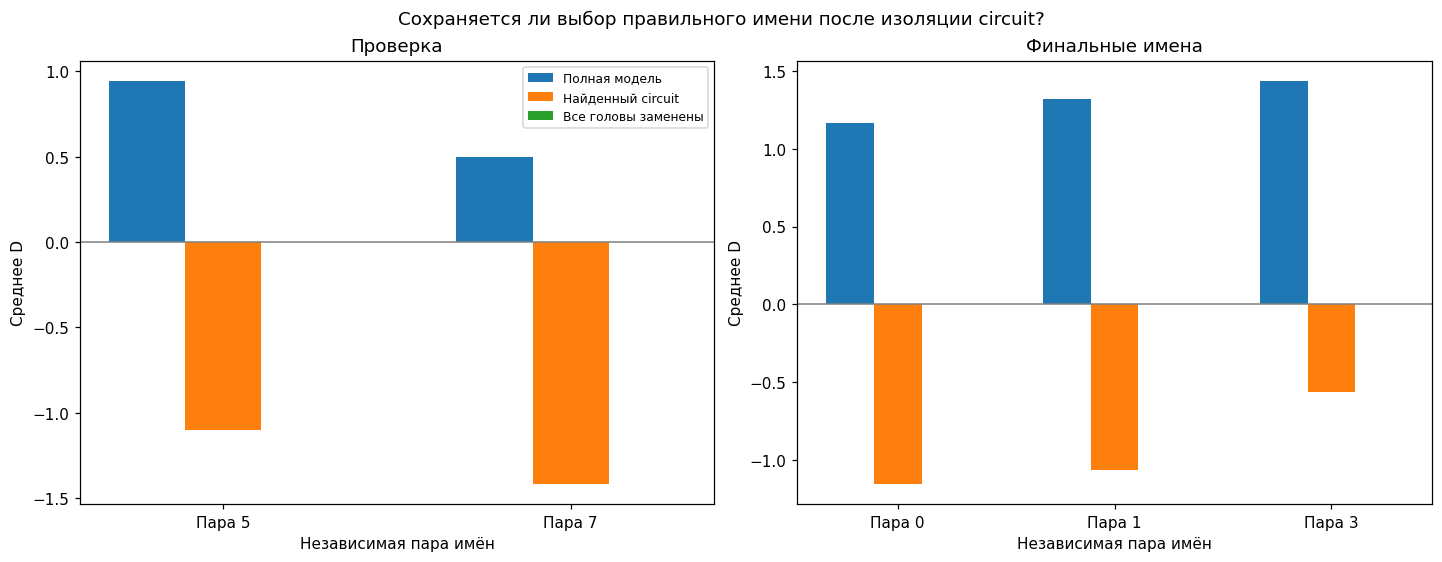

### Краткий итог

- Найдено и сохранено **12 голов** из 144.
- Проверочная выборка: **R = -1.745**.
- Финальная выборка: **R = -0.709**.
- **Интерпретация:** найденный набор голов при текущей mean ablation не сохраняет поведение полной модели: это отрицательный результат проверки достаточности, а не доказательство отсутствия IOI-механизма.

**Ограничения:** группы не доказаны только по attention; замена средними активациями может давать нетипичное внутреннее состояние; англоязычные 85,1% здесь не прямой бенчмарк.

In [12]:
# Этап 7. Проводим финальный тест и формируем вывод.
# Не меняем keep/senders/receivers после просмотра этого результата.
final_results,R_final=evaluate_circuit(final_valid,"FINAL")
final_results.to_csv(OUT/"final_circuit.csv",index=False)
summary={
    "модель":MODEL_ID,"ревизия":MODEL_REV,"голов_сохранено":len(keep),
    "головы":[f"L{l}H{h}" for l,h in sorted(keep)],
    "validation_R":float(R_validation),"final_R":float(R_final),
    "проверенных_финальных_примеров":len(final_valid)
}
(OUT/"experiment_summary.json").write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding="utf-8")
comparison=pd.DataFrame([
    {"Эксперимент":"GPT-2 Small, исходный приложенный ноутбук", "Голов":26,"R":"85,1% на основном шаблоне", "Группы":"7 заданных по статье"},
    {"Эксперимент":"ruGPT3Small, найденный circuit", "Голов":len(keep),
     "R":f"{R_final:.1%}" if np.isfinite(R_final) else "не определено", "Группы":"гипотезы, требуют отдельных функциональных подтверждений"}
])
display(comparison)

# Оцениваем вариацию финального R по парам имён, а не по отдельным симметричным строкам.
aggregated=final_results.groupby("pair_id")[["full","circuit","all_mean"]].mean()
rng=np.random.default_rng(SEED)
boots=[]
for _ in range(1000):
    sample=aggregated.iloc[rng.integers(0,len(aggregated),len(aggregated))].mean()
    denom=sample["full"]-sample["all_mean"]
    if abs(denom)>1e-6: boots.append((sample["circuit"]-sample["all_mean"])/denom)
if boots: print("95% bootstrap-интервал R по парам имён:", np.percentile(boots,[2.5,97.5]).round(3))
print("Файлы графиков, таблиц и JSON:",OUT.resolve())
print("Нельзя объявлять обнаруженными те группы, для которых нет диагностических и причинных подтверждений.")

# Наглядное сравнение на валидации и финальном наборе: не смешиваем с английскими 85,1%.
fig, axs = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for ax, data, name in ((axs[0], circuit_validation, "Проверка"), (axs[1], final_results, "Финальные имена")):
    grouped = data.groupby("pair_id")[["full", "circuit", "all_mean"]].mean()
    p = np.arange(len(grouped))
    ax.bar(p - .22, grouped["full"], width=.22, label="Полная модель")
    ax.bar(p, grouped["circuit"], width=.22, label="Найденный circuit")
    ax.bar(p + .22, grouped["all_mean"], width=.22, label="Все головы заменены")
    ax.axhline(0, color="gray", linewidth=1)
    ax.set_xticks(p, [f"Пара {i}" for i in grouped.index])
    ax.set(xlabel="Независимая пара имён", ylabel="Среднее D", title=name)
axs[0].legend(fontsize=8, loc="best")
fig.suptitle("Сохраняется ли выбор правильного имени после изоляции circuit?")
fig.savefig(OUT / "circuit_final_by_pair.png", dpi=180)
plt.show()

# Текстовый вывод формируется из фактических результатов, а не вписан заранее.
from IPython.display import Markdown
rv = float(R_validation)
rf = float(R_final)
if not np.isfinite(rf):
    verdict = "на финальной выборке коэффициент R не определён: нужен другой контроль или метрика"
elif rf < 0:
    verdict = ("найденный набор голов при текущей mean ablation не сохраняет поведение полной модели: "
               "это отрицательный результат проверки достаточности, а не доказательство отсутствия IOI-механизма")
elif rf < 1:
    verdict = "на финальной выборке выделенный набор сохраняет часть эффекта; функции групп нуждаются в дополнительных проверках"
else:
    verdict = "на финальной выборке эффект не меньше эффекта полной модели; надо проверить устойчивость и артефакты вмешательства"
display(Markdown(
    f"### Краткий итог\n\n"
    f"- Найдено и сохранено **{len(keep)} голов** из 144.\n"
    f"- Проверочная выборка: **R = {rv:+.3f}**.\n"
    f"- Финальная выборка: **R = {rf:+.3f}**.\n"
    f"- **Интерпретация:** {verdict}.\n\n"
    "**Ограничения:** группы не доказаны только по attention; замена средними активациями "
    "может давать нетипичное внутреннее состояние; англоязычные 85,1% здесь не прямой бенчмарк."
))